In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer,
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TARGET = "stress_level"
HOLDOUT_SIZE = 0.20
CV_SPLITS = 5
CV_SEEDS = [42, 123, 2026]
PRIMARY_METRIC = "f1_weighted"

np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")
print("Primary selection metric:", PRIMARY_METRIC)

Libraries imported successfully.
Primary selection metric: f1_weighted


In [3]:
# CSV ফাইলের সম্ভাব্য অবস্থানগুলো পরীক্ষা করি
possible_paths = [
    Path("StressLevelDataset.csv"),
    Path.cwd() / "StressLevelDataset.csv",
    Path("/mnt/data/StressLevelDataset.csv"),
]

data_path = next((path for path in possible_paths if path.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "StressLevelDataset.csv was not found. Place the CSV file in the same folder as this notebook."
    )

df = pd.read_csv(data_path)
df.columns = df.columns.str.strip()

print("Dataset path:", data_path.resolve())
print("Dataset shape:", df.shape)
display(df.head())

Dataset path: C:\Users\momen\OneDrive - vu.edu.bd\Desktop\8th Semester\ML\LAB\MLLAB\2nd paper\MLLAB-main\StressLevelDataset.csv
Dataset shape: (1100, 21)


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


In [4]:
# প্রয়োজনীয় target column এবং dataset structure যাচাই করি
if TARGET not in df.columns:
    raise ValueError(f"Required target column '{TARGET}' is missing.")

if df.columns.duplicated().any():
    duplicated_columns = df.columns[df.columns.duplicated()].tolist()
    raise ValueError(f"Duplicate column names found: {duplicated_columns}")

feature_columns = [column for column in df.columns if column != TARGET]

audit_summary = pd.DataFrame({
    "item": [
        "Number of rows",
        "Number of columns",
        "Number of predictors",
        "Total missing values",
        "Duplicate rows",
        "Target unique values",
    ],
    "value": [
        len(df),
        len(df.columns),
        len(feature_columns),
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int(df[TARGET].nunique()),
    ],
})

display(audit_summary)
display(pd.DataFrame({
    "column": df.columns,
    "data_type": [str(dtype) for dtype in df.dtypes],
    "missing_values": [int(value) for value in df.isna().sum().values],
    "unique_values": [int(df[column].nunique(dropna=False)) for column in df.columns],
}))
display(df[TARGET].value_counts(dropna=False).sort_index().rename_axis("class").to_frame("count"))

,item,value
0,Number of rows,1100
1,Number of columns,21
2,Number of predictors,20
3,Total missing values,0
4,Duplicate rows,0
5,Target unique values,3


,column,data_type,missing_values,unique_values
0,anxiety_level,int64,0,22
1,self_esteem,int64,0,31
2,mental_health_history,int64,0,2
3,depression,int64,0,28
4,headache,int64,0,6
5,blood_pressure,int64,0,3
6,sleep_quality,int64,0,6
7,breathing_problem,int64,0,6
8,noise_level,int64,0,6
9,living_conditions,int64,0,6


,count
class,
0,373
1,358
2,369



বর্তমান workflow-এর baseline model-গুলো numeric predictors প্রত্যাশা করে। তাই non-numeric predictor বা missing value থাকলে model training-এর আগে execution থামবে, যাতে অনিচ্ছাকৃত data handling না হয়।

In [4]:
# Predictor ও target-এর data quality যাচাই করি
if df[TARGET].isna().any():
    raise ValueError("The target column contains missing values.")

if df[feature_columns].isna().any().any():
    missing_columns = df[feature_columns].columns[df[feature_columns].isna().any()].tolist()
    raise ValueError(f"Predictor columns contain missing values: {missing_columns}")

non_numeric_features = df[feature_columns].select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric_features:
    raise TypeError(f"Non-numeric predictors require an explicit preprocessing plan: {non_numeric_features}")

if df[TARGET].nunique() < 2:
    raise ValueError("The target must contain at least two classes.")

print("Data validation passed.")
print("Target class labels:", sorted(df[TARGET].unique().tolist()))
print("Target labels are retained as numeric classes; semantic names require dataset documentation.")

Data validation passed.
Target class labels: [0, 1, 2]
Target labels are retained as numeric classes; semantic names require dataset documentation.


# Feature-to-domain mapping

২০টি predictor-কে পাঁচটি প্রাথমিক domain-এ ভাগ করা হয়েছে। এই mapping feature name-এর অর্থের ভিত্তিতে করা; এটি গবেষণার একটি operational definition। ভবিষ্যৎ বিশ্লেষণে mapping পরিবর্তন করলে সব ablation ফলাফলের সঙ্গে সেই পরিবর্তন নথিভুক্ত করতে হবে।

In [8]:
# প্রতিটি predictor-কে একটি প্রাথমিক domain-এ বরাদ্দ করি
domain_mapping = {
    "Psychological": [
        "anxiety_level",
        "self_esteem",
        "mental_health_history",
        "depression",
    ],
    "Physiological": [
        "headache",
        "blood_pressure",
        "sleep_quality",
        "breathing_problem",
    ],
    "Social": [
        "social_support",
        "peer_pressure",
        "extracurricular_activities",
        "bullying",
    ],
    "Environmental": [
        "noise_level",
        "living_conditions",
        "safety",
        "basic_needs",
    ],
    "Academic": [
        "academic_performance",
        "study_load",
        "teacher_student_relationship",
        "future_career_concerns",
    ],
}

# প্রতিটি feature-এর domain rationale নির্ধারণ করি
feature_rationale = {
    "anxiety_level": "Measures anxiety and is assigned to the psychological domain.",
    "self_esteem": "Represents self-evaluation and is assigned to the psychological domain.",
    "mental_health_history": "Represents previous mental health history.",
    "depression": "Represents depressive symptoms or depression-related status.",
    "headache": "Represents a physical symptom.",
    "blood_pressure": "Represents a physiological indicator.",
    "sleep_quality": "Represents sleep quality; it may also relate to mental health.",
    "breathing_problem": "Represents a physical symptom.",
    "social_support": "Represents perceived or available social support.",
    "peer_pressure": "Represents social pressure from peers.",
    "extracurricular_activities": "Represents extracurricular participation and may overlap with academic engagement.",
    "bullying": "Represents bullying or harassment as a social experience.",
    "noise_level": "Represents noise in the surrounding environment.",
    "living_conditions": "Represents housing or living conditions.",
    "safety": "Represents safety conditions or perceived safety.",
    "basic_needs": "Represents fulfillment of basic needs and may overlap with socioeconomic factors.",
    "academic_performance": "Represents academic performance.",
    "study_load": "Represents the amount or pressure of academic work.",
    "teacher_student_relationship": "Represents teacher-student relations and may overlap with the social domain.",
    "future_career_concerns": "Represents future career concerns and may overlap with psychological factors.",
}

mapped_features = [feature for features in domain_mapping.values() for feature in features]
missing_from_mapping = sorted(set(feature_columns) - set(mapped_features))
unknown_in_mapping = sorted(set(mapped_features) - set(feature_columns))
duplicate_mappings = sorted({feature for feature in mapped_features if mapped_features.count(feature) > 1})

if missing_from_mapping or unknown_in_mapping or duplicate_mappings:
    raise ValueError(
        f"Domain mapping validation failed. Missing={missing_from_mapping}; "
        f"Unknown={unknown_in_mapping}; Duplicated={duplicate_mappings}"
    )

mapping_table = pd.DataFrame([
    {
        "feature": feature,
        "assigned_domain": domain,
        "mapping_basis": "Semantic interpretation of feature names",
        "rationale": feature_rationale[feature],
    }
    for domain, features in domain_mapping.items()
    for feature in features
])

display(mapping_table)
display(mapping_table.groupby("assigned_domain").size().rename("feature_count").to_frame())
print("Domain mapping validation passed for", len(mapped_features), "predictors.")

,feature,assigned_domain,mapping_basis,rationale
0,anxiety_level,Psychological,Semantic interpretation of feature names,Measures anxiety and is assigned to the psycho...
1,self_esteem,Psychological,Semantic interpretation of feature names,Represents self-evaluation and is assigned to ...
2,mental_health_history,Psychological,Semantic interpretation of feature names,Represents previous mental health history.
3,depression,Psychological,Semantic interpretation of feature names,Represents depressive symptoms or depression-r...
4,headache,Physiological,Semantic interpretation of feature names,Represents a physical symptom.
5,blood_pressure,Physiological,Semantic interpretation of feature names,Represents a physiological indicator.
6,sleep_quality,Physiological,Semantic interpretation of feature names,Represents sleep quality; it may also relate t...
7,breathing_problem,Physiological,Semantic interpretation of feature names,Represents a physical symptom.
8,social_support,Social,Semantic interpretation of feature names,Represents perceived or available social support.
9,peer_pressure,Social,Semantic interpretation of feature names,Represents social pressure from peers.


,feature_count
assigned_domain,
Academic,4
Environmental,4
Physiological,4
Psychological,4
Social,4


Domain mapping validation passed for 20 predictors.


## Mapping-limitations

কিছু predictor একাধিক domain-এর সঙ্গে সম্পর্কিত হতে পারে। যেমন `sleep_quality`, `extracurricular_activities`, `teacher_student_relationship`, `future_career_concerns` এবং `basic_needs`। এখানে প্রতিটি feature-কে একটিমাত্র primary domain দেওয়া হয়েছে, যাতে ablation স্পষ্ট ও পুনরুৎপাদনযোগ্য থাকে। ফলাফল ব্যাখ্যার সময় এই সীমাবদ্ধতা উল্লেখ করতে হবে।

In [10]:
# সম্ভাব্য overlapping feature-গুলোর সীমাবদ্ধতা নথিভুক্ত করি
ambiguous_features = pd.DataFrame([
    {"feature": "sleep_quality", "primary_domain": "Physiological", "possible_overlap": "Psychological"},
    {"feature": "extracurricular_activities", "primary_domain": "Social", "possible_overlap": "Academic"},
    {"feature": "teacher_student_relationship", "primary_domain": "Academic", "possible_overlap": "Social"},
    {"feature": "future_career_concerns", "primary_domain": "Academic", "possible_overlap": "Psychological"},
    {"feature": "basic_needs", "primary_domain": "Environmental", "possible_overlap": "Socioeconomic"},
])
display(ambiguous_features)

,feature,primary_domain,possible_overlap
0,sleep_quality,Physiological,Psychological
1,extracurricular_activities,Social,Academic
2,teacher_student_relationship,Academic,Social
3,future_career_concerns,Academic,Psychological
4,basic_needs,Environmental,Socioeconomic


# Stratified 80/20 train-test split

Training set-এর ভেতরেই cross-validation এবং model selection হবে। Holdout set শুধুমাত্র নির্বাচিত final model-এর evaluation-এর জন্য সংরক্ষিত থাকবে। Stratification target class proportions যতটা সম্ভব বজায় রাখে।

In [11]:
# Target ও predictors আলাদা করে stratified split তৈরি করি
X = df[feature_columns].copy()
y = df[TARGET].copy()

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X,
    y,
    test_size=HOLDOUT_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

split_summary = pd.DataFrame({
    "partition": ["Full dataset", "Training", "Holdout"],
    "samples": [len(df), len(X_train), len(X_holdout)],
    "percentage": [100.0, 100.0 * len(X_train) / len(df), 100.0 * len(X_holdout) / len(df)],
})
display(split_summary)

class_distribution = pd.concat(
    [
        y.value_counts(normalize=True).sort_index().rename("full_dataset"),
        y_train.value_counts(normalize=True).sort_index().rename("training"),
        y_holdout.value_counts(normalize=True).sort_index().rename("holdout"),
    ],
    axis=1,
).fillna(0)
display((100 * class_distribution).round(2).rename_axis("class").rename_axis(None, axis=1))

assert len(X_train) + len(X_holdout) == len(df)
assert set(X_train.index).isdisjoint(set(X_holdout.index))
assert list(X_train.columns) == feature_columns
assert list(X_holdout.columns) == feature_columns
print("Train-holdout split validation passed.")

,partition,samples,percentage
0,Full dataset,1100,100.0
1,Training,880,80.0
2,Holdout,220,20.0


,full_dataset,training,holdout
class,,,
0,33.91,33.98,33.64
1,32.55,32.50,32.73
2,33.55,33.52,33.64


Train-holdout split validation passed.


# Baseline model evaluation

In [15]:

# প্রয়োজনীয় লাইব্রেরি ইমপোর্ট করি
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    matthews_corrcoef
)

from IPython.display import display
from xgboost import XGBClassifier

# গবেষণার কনফিগারেশন নির্ধারণ করি
RANDOM_STATE = 42
PRIMARY_METRIC = "F1_Macro"
CLASS_LABELS = np.sort(np.unique(np.asarray(y_train)))

# নয়টি baseline model নির্ধারণ করি
baseline_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            probability=True,
            random_state=RANDOM_STATE
        ))
    ]),

    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.1,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ]),

    "Naive Bayes": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GaussianNB())
    ]),

    "Stochastic Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(
            random_state=RANDOM_STATE
        ))
    ]),

    "AdaBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", AdaBoostClassifier(
            random_state=RANDOM_STATE
        ))
    ])
}

# ফলাফল ও trained model সংরক্ষণের container তৈরি করি
baseline_results = []
baseline_fitted_models = {}

# প্রতিটি model train করে holdout set-এ মূল্যায়ন করি
for model_name, pipeline in baseline_models.items():
    fitted_model = clone(pipeline)
    fitted_model.fit(X_train, y_train)

    y_pred = fitted_model.predict(X_holdout)
    y_proba = fitted_model.predict_proba(X_holdout)

    baseline_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_holdout, y_pred),

        "Precision_Macro": precision_score(
            y_holdout,
            y_pred,
            labels=CLASS_LABELS,
            average="macro",
            zero_division=0
        ),

        "Recall_Macro": recall_score(
            y_holdout,
            y_pred,
            labels=CLASS_LABELS,
            average="macro",
            zero_division=0
        ),

        "F1_Macro": f1_score(
            y_holdout,
            y_pred,
            labels=CLASS_LABELS,
            average="macro",
            zero_division=0
        ),

        "F1_Weighted": f1_score(
            y_holdout,
            y_pred,
            labels=CLASS_LABELS,
            average="weighted",
            zero_division=0
        ),

        "Balanced_Accuracy": balanced_accuracy_score(
            y_holdout,
            y_pred
        ),

        "ROC_AUC_Weighted_OvR": roc_auc_score(
            y_holdout,
            y_proba,
            labels=CLASS_LABELS,
            multi_class="ovr",
            average="weighted"
        ),

        "MCC": matthews_corrcoef(
            y_holdout,
            y_pred
        )
    })

    baseline_fitted_models[model_name] = fitted_model

    print(f"Completed: {model_name}")

# Primary metric অনুযায়ী model সাজাই
baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df = baseline_results_df.sort_values(
    by=PRIMARY_METRIC,
    ascending=False
).reset_index(drop=True)

# শুধু metrics table প্রদর্শন করি
display(baseline_results_df.round(4))

# সেরা baseline model-এর ফলাফল দেখাই
best_baseline_model = baseline_results_df.iloc[0]["Model"]
best_baseline_f1 = baseline_results_df.iloc[0]["F1_Macro"]

print("Primary Metric:", PRIMARY_METRIC)
print("Best Baseline Model:", best_baseline_model)
print("Best Holdout Macro F1:", round(best_baseline_f1, 4))


Completed: Logistic Regression
Completed: KNN
Completed: Decision Tree
Completed: Random Forest
Completed: SVM
Completed: XGBoost
Completed: Naive Bayes
Completed: Stochastic Gradient Boosting
Completed: AdaBoost


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,Balanced_Accuracy,ROC_AUC_Weighted_OvR,MCC
0,Random Forest,0.8864,0.8874,0.8868,0.8863,0.8861,0.8868,0.9831,0.8303
1,AdaBoost,0.8864,0.8885,0.8866,0.8858,0.8857,0.8866,0.9746,0.8312
2,Logistic Regression,0.8818,0.8818,0.8821,0.8820,0.8817,0.8821,0.9853,0.8227
3,XGBoost,0.8818,0.8824,0.8823,0.8815,0.8813,0.8823,0.9830,0.8235
4,Naive Bayes,0.8773,0.8894,0.8774,0.8792,0.8787,0.8774,0.9708,0.8202
5,SVM,0.8773,0.8775,0.8776,0.8774,0.8771,0.8776,0.9845,0.8161
6,Stochastic Gradient Boosting,0.8727,0.8730,0.8732,0.8724,0.8722,0.8732,0.9825,0.8098
7,Decision Tree,0.8545,0.8556,0.8550,0.8543,0.8542,0.8550,0.8911,0.7828
8,KNN,0.8500,0.8515,0.8506,0.8499,0.8497,0.8506,0.9530,0.7761


Primary Metric: F1_Macro
Best Baseline Model: Random Forest
Best Holdout Macro F1: 0.8863


In [16]:
# প্রয়োজনীয় cross-validation tools ইমপোর্ট করি
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer

# CV-এর কনফিগারেশন নির্ধারণ করি
CV_SPLITS = 5
CV_SEEDS = [42, 123, 2026]

# সব cell-এ একই metric scoring ব্যবহার করি
SCORING = {
    "Accuracy": "accuracy",
    "Precision_Macro": "precision_macro",
    "Recall_Macro": "recall_macro",
    "F1_Macro": "f1_macro",
    "F1_Weighted": "f1_weighted",
    "Balanced_Accuracy": "balanced_accuracy",
    "ROC_AUC_Weighted_OvR": "roc_auc_ovr_weighted",
    "MCC": make_scorer(matthews_corrcoef)
}

# পুনর্ব্যবহারযোগ্য CV evaluation function তৈরি করি
def evaluate_cv(X_data, y_data, models, seeds=CV_SEEDS):
    fold_rows = []

    for model_name, pipeline in models.items():
        for seed in seeds:
            cv = StratifiedKFold(
                n_splits=CV_SPLITS,
                shuffle=True,
                random_state=seed
            )

            scores = cross_validate(
                clone(pipeline),
                X_data,
                y_data,
                cv=cv,
                scoring=SCORING,
                return_train_score=False,
                n_jobs=1,
                error_score="raise"
            )

            for fold_index in range(CV_SPLITS):
                row = {
                    "Model": model_name,
                    "Seed": seed,
                    "Fold": fold_index + 1
                }

                for metric_name in SCORING:
                    row[metric_name] = scores[
                        f"test_{metric_name}"
                    ][fold_index]

                fold_rows.append(row)

    fold_df = pd.DataFrame(fold_rows)

    metric_names = list(SCORING.keys())
    summary_rows = []

    for model_name, group in fold_df.groupby("Model", sort=False):
        row = {"Model": model_name}

        for metric_name in metric_names:
            row[f"{metric_name}_Mean"] = group[metric_name].mean()
            row[f"{metric_name}_SD"] = group[metric_name].std(ddof=1)

        summary_rows.append(row)

    summary_df = pd.DataFrame(summary_rows)
    summary_df = summary_df.sort_values(
        "F1_Macro_Mean", ascending=False
    ).reset_index(drop=True)

    return fold_df, summary_df

# নয়টি model-এর repeated stratified CV চালাই
cv_fold_results_df, cv_results_df = evaluate_cv(
    X_train, y_train, baseline_models
)

# প্রতিটি model-এর mean ও standard deviation দেখাই
display(cv_results_df.round(4))

print("Best CV model:", cv_results_df.iloc[0]["Model"])

,Model,Accuracy_Mean,Accuracy_SD,Precision_Macro_Mean,Precision_Macro_SD,Recall_Macro_Mean,Recall_Macro_SD,F1_Macro_Mean,F1_Macro_SD,F1_Weighted_Mean,F1_Weighted_SD,Balanced_Accuracy_Mean,Balanced_Accuracy_SD,ROC_AUC_Weighted_OvR_Mean,ROC_AUC_Weighted_OvR_SD,MCC_Mean,MCC_SD
0,Logistic Regression,0.8830,0.0226,0.8855,0.0231,0.8829,0.0228,0.8831,0.0228,0.8830,0.0228,0.8829,0.0228,0.9816,0.0083,0.8254,0.0340
1,Naive Bayes,0.8807,0.0164,0.8948,0.0153,0.8805,0.0163,0.8821,0.0160,0.8820,0.0161,0.8805,0.0163,0.9725,0.0091,0.8268,0.0233
2,Stochastic Gradient Boosting,0.8788,0.0220,0.8800,0.0227,0.8787,0.0220,0.8786,0.0221,0.8787,0.0220,0.8787,0.0220,0.9826,0.0081,0.8188,0.0332
3,XGBoost,0.8780,0.0214,0.8796,0.0218,0.8780,0.0212,0.8781,0.0212,0.8781,0.0213,0.8780,0.0212,0.9831,0.0068,0.8177,0.0323
4,AdaBoost,0.8780,0.0232,0.8802,0.0224,0.8780,0.0231,0.8779,0.0230,0.8780,0.0231,0.8780,0.0231,0.9661,0.0120,0.8180,0.0346
5,Decision Tree,0.8769,0.0255,0.8785,0.0251,0.8769,0.0254,0.8769,0.0255,0.8770,0.0256,0.8769,0.0254,0.9077,0.0191,0.8161,0.0379
6,Random Forest,0.8705,0.0250,0.8732,0.0268,0.8703,0.0249,0.8705,0.0252,0.8705,0.0252,0.8703,0.0249,0.9817,0.0072,0.8067,0.0381
7,SVM,0.8633,0.0225,0.8681,0.0227,0.8631,0.0226,0.8633,0.0224,0.8634,0.0224,0.8631,0.0226,0.9798,0.0081,0.7970,0.0338
8,KNN,0.8614,0.0300,0.8668,0.0298,0.8619,0.0299,0.8617,0.0300,0.8619,0.0301,0.8619,0.0299,0.9575,0.0124,0.7947,0.0447


Best CV model: Logistic Regression


In [14]:
# পাঁচটি domain-এর feature mapping নির্ধারণ করি
domain_mapping = {
    "Psychological": [
        "anxiety_level",
        "self_esteem",
        "mental_health_history",
        "depression"
    ],
    "Physiological": [
        "headache",
        "blood_pressure",
        "sleep_quality",
        "breathing_problem"
    ],
    "Social": [
        "social_support",
        "peer_pressure",
        "extracurricular_activities",
        "bullying"
    ],
    "Environmental": [
        "noise_level",
        "living_conditions",
        "safety",
        "basic_needs"
    ],
    "Academic": [
        "academic_performance",
        "study_load",
        "teacher_student_relationship",
        "future_career_concerns"
    ]
}

# Feature mapping সম্পূর্ণ ও দ্বন্দ্বমুক্ত কি না যাচাই করি
all_mapped_features = [
    feature
    for features in domain_mapping.values()
    for feature in features
]

missing_from_mapping = sorted(
    set(X_train.columns) - set(all_mapped_features)
)
unknown_features = sorted(
    set(all_mapped_features) - set(X_train.columns)
)
duplicate_features = sorted({
    feature for feature in all_mapped_features
    if all_mapped_features.count(feature) > 1
})

if missing_from_mapping or unknown_features or duplicate_features:
    raise ValueError(
        f"Missing from mapping: {missing_from_mapping}\n"
        f"Unknown features: {unknown_features}\n"
        f"Duplicate features: {duplicate_features}"
    )

# Full, domain-removed এবং domain-only configurations তৈরি করি
domain_configurations = {
    "Full Features": list(X_train.columns)
}

for domain, features in domain_mapping.items():
    domain_configurations[f"Without {domain}"] = [
        feature for feature in X_train.columns
        if feature not in features
    ]

    domain_configurations[f"Only {domain}"] = [
        feature for feature in features
        if feature in X_train.columns
    ]

# প্রতিটি configuration-এ সব model-এর CV চালাই
ablation_fold_results = []
ablation_summary_results = []

for configuration, selected_features in domain_configurations.items():
    if not selected_features:
        continue

    print(f"Evaluating: {configuration}")

    X_subset = X_train[selected_features].copy()

    fold_df, summary_df = evaluate_cv(
        X_subset, y_train, baseline_models
    )

    fold_df.insert(0, "Configuration", configuration)
    summary_df.insert(0, "Configuration", configuration)

    ablation_fold_results.append(fold_df)
    ablation_summary_results.append(summary_df)

# সব domain ablation ফলাফল একত্র করি
ablation_fold_results_df = pd.concat(
    ablation_fold_results, ignore_index=True
)

ablation_results_df = pd.concat(
    ablation_summary_results, ignore_index=True
)

# Primary metric অনুযায়ী ফলাফল সাজাই
ablation_results_df = ablation_results_df.sort_values(
    "F1_Macro_Mean", ascending=False
).reset_index(drop=True)

# প্রতিটি configuration-এর performance দেখাই
display(
    ablation_results_df[
        [
            "Configuration",
            "Model",
            "F1_Macro_Mean",
            "F1_Macro_SD",
            "Accuracy_Mean",
            "Balanced_Accuracy_Mean",
            "MCC_Mean",
            "ROC_AUC_Weighted_OvR_Mean"
        ]
    ].round(4)
)

Evaluating: Full Features
Evaluating: Without Psychological
Evaluating: Only Psychological
Evaluating: Without Physiological
Evaluating: Only Physiological
Evaluating: Without Social
Evaluating: Only Social
Evaluating: Without Environmental
Evaluating: Only Environmental
Evaluating: Without Academic
Evaluating: Only Academic


,Configuration,Model,F1_Macro_Mean,F1_Macro_SD,Accuracy_Mean,Balanced_Accuracy_Mean,MCC_Mean,ROC_AUC_Weighted_OvR_Mean
0,Only Social,Decision Tree,0.8881,0.0265,0.8879,0.8880,0.8327,0.9195
1,Without Academic,Logistic Regression,0.8874,0.0252,0.8871,0.8870,0.8317,0.9801
2,Without Environmental,Logistic Regression,0.8866,0.0195,0.8864,0.8863,0.8307,0.9816
3,Without Environmental,Stochastic Gradient Boosting,0.8862,0.0234,0.8864,0.8864,0.8303,0.9841
4,Without Social,Logistic Regression,0.8859,0.0238,0.8856,0.8853,0.8300,0.9764
...,...,...,...,...,...,...,...,...
94,Only Environmental,XGBoost,0.8614,0.0261,0.8614,0.8613,0.7932,0.9681
95,Only Environmental,Random Forest,0.8601,0.0229,0.8602,0.8602,0.7912,0.9748
96,Only Environmental,Decision Tree,0.8601,0.0198,0.8602,0.8603,0.7914,0.8941
97,Only Environmental,AdaBoost,0.8597,0.0207,0.8598,0.8596,0.7910,0.9409


## ধাপ 4.1: Baseline model নির্বাচন

Training-set cross-validation-এর গড় weighted F1 অনুযায়ী সেরা model নির্বাচন করা হবে। Holdout ফলাফল দেখার আগে এই সিদ্ধান্ত নেওয়া হবে, যাতে holdout performance দেখে model বেছে নেওয়ার bias না আসে।

In [9]:
# Cross-validation weighted F1 অনুযায়ী সেরা baseline model নির্বাচন করি
best_model_name = baseline_summary.iloc[0]["model"]
best_cv_weighted_f1 = float(baseline_summary.iloc[0]["f1_weighted_mean"])

final_pipeline = build_model_pipelines(RANDOM_STATE)[best_model_name]
final_pipeline.fit(X_train, y_train)

print("Selected model:", best_model_name)
print("Mean cross-validated weighted F1:", round(best_cv_weighted_f1, 4))

Selected model: Logistic Regression
Mean cross-validated weighted F1: 0.883


# ধাপ 5: Holdout set-এ final evaluation

নির্বাচিত pipeline পুরো training set-এ fit করা হয়েছে। এখন holdout set-এ একবার final evaluation করা হবে। এই ফলাফল baseline-এর held-out estimate হিসেবে রিপোর্ট করতে হবে; holdout দেখে পরবর্তী tuning করা উচিত নয়।

,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_weighted,f1_macro,mcc
0,Logistic Regression,0.8818,0.8821,0.8818,0.8821,0.8817,0.882,0.8227


Classification report:
              precision    recall  f1-score   support

           0       0.86      0.85      0.86        74
           1       0.90      0.92      0.91        72
           2       0.88      0.88      0.88        74

    accuracy                           0.88       220
   macro avg       0.88      0.88      0.88       220
weighted avg       0.88      0.88      0.88       220



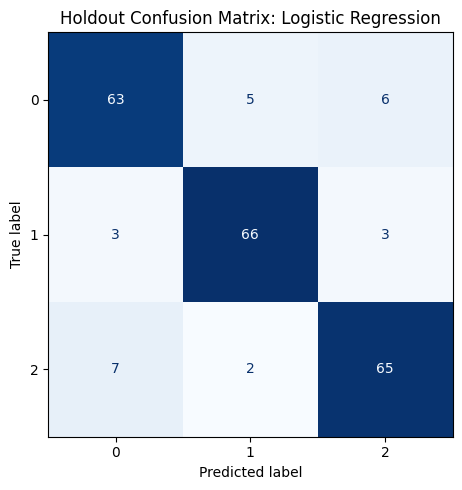

In [10]:
# সংরক্ষিত holdout set-এ final prediction তৈরি করি
y_holdout_pred = final_pipeline.predict(X_holdout)

holdout_metrics = {
    "model": best_model_name,
    "accuracy": accuracy_score(y_holdout, y_holdout_pred),
    "balanced_accuracy": balanced_accuracy_score(y_holdout, y_holdout_pred),
    "precision_macro": precision_score(y_holdout, y_holdout_pred, average="macro", zero_division=0),
    "recall_macro": recall_score(y_holdout, y_holdout_pred, average="macro", zero_division=0),
    "f1_weighted": f1_score(y_holdout, y_holdout_pred, average="weighted", zero_division=0),
    "f1_macro": f1_score(y_holdout, y_holdout_pred, average="macro", zero_division=0),
    "mcc": matthews_corrcoef(y_holdout, y_holdout_pred),
}
holdout_metrics_table = pd.DataFrame([holdout_metrics])
display(holdout_metrics_table.round(4))

print("Classification report:")
print(classification_report(y_holdout, y_holdout_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_holdout,
    y_holdout_pred,
    labels=sorted(y.unique()),
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"Holdout Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

# ধাপ 6: Domain-level ablation study

দুটি ablation strategy ব্যবহার করা হবে:

- **Domain removal:** একটি domain-এর feature বাদ দিয়ে বাকি সব feature দিয়ে model train করা।
- **Single-domain-only:** কেবল একটি domain-এর feature ব্যবহার করে model train করা।

Ablation-এর জন্য full-feature baseline CV-তে নির্বাচিত model-টিই ব্যবহার করা হবে, যাতে domain comparison একই model family-তে হয় এবং computational cost নিয়ন্ত্রণে থাকে। একই CV seed/fold scheme ব্যবহার করা হবে। তুলনাগুলো training data-এর CV ফলাফলের ওপর নির্ভর করবে। Domain removal-এর score baseline-এর চেয়ে কম হলে সেই domain-এর তথ্য predictive performance-এ সহায়ক হতে পারে; তবে এটি causal importance প্রমাণ করে না।

In [11]:
# প্রতিটি domain-এর feature list তৈরি করি
all_domains = list(domain_mapping.keys())
ablation_feature_sets = {"All features": feature_columns.copy()}

for domain, features in domain_mapping.items():
    ablation_feature_sets[f"Without {domain}"] = [feature for feature in feature_columns if feature not in features]
    ablation_feature_sets[f"{domain} only"] = features.copy()

for config_name, features in ablation_feature_sets.items():
    if not features:
        raise ValueError(f"Configuration '{config_name}' has no features.")

print("Number of feature configurations:", len(ablation_feature_sets))
display(pd.DataFrame([
    {"configuration": name, "feature_count": len(features)}
    for name, features in ablation_feature_sets.items()
]))

Number of feature configurations: 11


,configuration,feature_count
0,All features,20
1,Without Psychological,16
2,Psychological only,4
3,Without Physiological,16
4,Physiological only,4
5,Without Social,16
6,Social only,4
7,Without Environmental,16
8,Environmental only,4
9,Without Academic,16


In [12]:
# সব feature configuration-এ একই CV protocol দিয়ে model performance গণনা করি
ablation_records = []

for seed in CV_SEEDS:
    cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=seed)

    for config_name, selected_features in ablation_feature_sets.items():
        model_name = best_model_name
        pipeline = build_model_pipelines(seed)[model_name]
        scores = cross_validate(
                pipeline,
                X_train[selected_features],
                y_train,
                cv=cv,
                scoring=SCORING,
                n_jobs=1,
                return_train_score=False,
                error_score="raise",
            )

        ablation_records.append({
            "configuration": config_name,
            "model": model_name,
            "seed": seed,
            "feature_count": len(selected_features),
            "accuracy": float(np.mean(scores["test_accuracy"])),
            "balanced_accuracy": float(np.mean(scores["test_balanced_accuracy"])),
            "f1_weighted": float(np.mean(scores["test_f1_weighted"])),
            "f1_macro": float(np.mean(scores["test_f1_macro"])),
            "mcc": float(np.mean(scores["test_mcc"])),
        })

ablation_seed_results = pd.DataFrame(ablation_records)
ablation_summary = (
    ablation_seed_results.groupby(["configuration", "model", "feature_count"])
    .agg(
        accuracy_mean=("accuracy", "mean"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        f1_weighted_mean=("f1_weighted", "mean"),
        f1_weighted_std=("f1_weighted", "std"),
        f1_macro_mean=("f1_macro", "mean"),
        mcc_mean=("mcc", "mean"),
    )
    .reset_index()
    .sort_values(["configuration", "f1_weighted_mean"], ascending=[True, False])
)

display(ablation_summary.round(4))

,configuration,model,feature_count,accuracy_mean,balanced_accuracy_mean,f1_weighted_mean,f1_weighted_std,f1_macro_mean,mcc_mean
0,Academic only,Logistic Regression,4,0.8686,0.8690,0.8692,0.0008,0.8689,0.8055
1,All features,Logistic Regression,20,0.8830,0.8829,0.8830,0.0049,0.8831,0.8254
2,Environmental only,Logistic Regression,4,0.8758,0.8763,0.8758,0.0035,0.8758,0.8154
3,Physiological only,Logistic Regression,4,0.8841,0.8835,0.8849,0.0018,0.8851,0.8297
4,Psychological only,Logistic Regression,4,0.8761,0.8765,0.8763,0.0022,0.8762,0.8155
5,Social only,Logistic Regression,4,0.8674,0.8673,0.8676,0.0008,0.8676,0.8022
6,Without Academic,Logistic Regression,16,0.8871,0.8870,0.8873,0.0016,0.8874,0.8317
7,Without Environmental,Logistic Regression,16,0.8864,0.8863,0.8865,0.0010,0.8866,0.8307
8,Without Physiological,Logistic Regression,16,0.8697,0.8697,0.8698,0.0031,0.8697,0.8059
9,Without Psychological,Logistic Regression,16,0.8784,0.8783,0.8787,0.0030,0.8788,0.8189


## ধাপ 6.1: Domain removal-এর baseline-এর সঙ্গে তুলনা

প্রতিটি model-এর জন্য full-feature CV weighted F1-এর সঙ্গে সংশ্লিষ্ট domain বাদ দেওয়ার score তুলনা করা হবে। `delta_f1_weighted` negative হলে domain বাদ দেওয়ার পর score কমেছে; positive হলে score বেড়েছে। ছোট পার্থক্যকে নিশ্চিত উন্নতি বা অবনতি হিসেবে না ধরে seed variability ও dataset সীমাবদ্ধতার সঙ্গে ব্যাখ্যা করতে হবে।

In [13]:
# একই model-এর baseline ও domain-removal ফলাফল তুলনা করি
full_feature_scores = (
    ablation_summary[ablation_summary["configuration"] == "All features"]
    [["model", "f1_weighted_mean"]]
    .rename(columns={"f1_weighted_mean": "full_feature_f1_weighted"})
)

removal_comparison = ablation_summary[
    ablation_summary["configuration"].str.startswith("Without ")
].merge(full_feature_scores, on="model", how="left")

removal_comparison["delta_f1_weighted"] = (
    removal_comparison["f1_weighted_mean"] - removal_comparison["full_feature_f1_weighted"]
)
removal_comparison["removed_domain"] = removal_comparison["configuration"].str.replace("Without ", "", regex=False)

display(
    removal_comparison[
        ["model", "removed_domain", "feature_count", "full_feature_f1_weighted", "f1_weighted_mean", "delta_f1_weighted"]
    ].sort_values(["model", "delta_f1_weighted"])
    .round(4)
)

,model,removed_domain,feature_count,full_feature_f1_weighted,f1_weighted_mean,delta_f1_weighted
2,Logistic Regression,Physiological,16,0.883,0.8698,-0.0132
3,Logistic Regression,Psychological,16,0.883,0.8787,-0.0043
4,Logistic Regression,Social,16,0.883,0.8859,0.0028
1,Logistic Regression,Environmental,16,0.883,0.8865,0.0035
0,Logistic Regression,Academic,16,0.883,0.8873,0.0043


## ধাপ 6.2: Single-domain-only ফলাফল

এই সারণি দেখাবে কোনো একটি domain-এর feature একাই কতটা predictive information বহন করে। Domain-গুলোর feature count সমান হলেও information content সমান নয়; তাই এটি domain-গুলোর সরাসরি causal ranking নয়।

In [14]:
# প্রতিটি domain-only configuration-এর সেরা model ও score দেখাই
single_domain_summary = ablation_summary[
    ablation_summary["configuration"].str.endswith(" only")
].copy()

best_single_domain = (
    single_domain_summary.sort_values("f1_weighted_mean", ascending=False)
    .groupby("configuration", as_index=False)
    .first()
    .sort_values("f1_weighted_mean", ascending=False)
)

display(best_single_domain[
    ["configuration", "model", "feature_count", "f1_weighted_mean", "f1_weighted_std", "f1_macro_mean", "mcc_mean"]
].round(4))

,configuration,model,feature_count,f1_weighted_mean,f1_weighted_std,f1_macro_mean,mcc_mean
2,Physiological only,Logistic Regression,4,0.8849,0.0018,0.8851,0.8297
3,Psychological only,Logistic Regression,4,0.8763,0.0022,0.8762,0.8155
1,Environmental only,Logistic Regression,4,0.8758,0.0035,0.8758,0.8154
0,Academic only,Logistic Regression,4,0.8692,0.0008,0.8689,0.8055
4,Social only,Logistic Regression,4,0.8676,0.0008,0.8676,0.8022


# ধাপ 7: SHAP explainability

SHAP analysis নির্বাচিত baseline pipeline-এর fitted model-এর ওপর চালানো হবে। Tree-based model-এর জন্য TreeExplainer এবং Logistic Regression-এর জন্য LinearExplainer ব্যবহার করা হবে। SHAP values predictive model-এর output-এ feature contribution ব্যাখ্যা করে; এগুলো causal effect বা intervention effect নয়।

SHAP API-তে version অনুযায়ী output shape আলাদা হতে পারে। নিচের code সেই পার্থক্য সামলানোর চেষ্টা করবে এবং failure হলে notebook-এর বাকি অংশ চালানো বন্ধ না করে warning দেখাবে।

In [15]:
# SHAP library পাওয়া গেলে fitted model-এর feature contributions গণনা করি
shap_available = False
shap_values_array = None
shap_feature_names = X_train.columns.tolist()
shap_class_labels = sorted(y_train.unique().tolist())

try:
    import shap

    fitted_estimator = final_pipeline.named_steps["model"]
    X_explain = X_holdout.copy()
    X_background = X_train.sample(n=min(100, len(X_train)), random_state=RANDOM_STATE)

    if best_model_name == "Logistic Regression":
        scaler = final_pipeline.named_steps["scaler"]
        background_transformed = scaler.transform(X_background)
        explain_transformed = scaler.transform(X_explain)
        explainer = shap.LinearExplainer(fitted_estimator, background_transformed)
        raw_shap_values = explainer.shap_values(explain_transformed)
    else:
        explainer = shap.TreeExplainer(fitted_estimator)
        raw_shap_values = explainer.shap_values(X_explain)

    if isinstance(raw_shap_values, list):
        shap_values_array = np.stack([np.asarray(values) for values in raw_shap_values], axis=0)
        shap_values_array = np.moveaxis(shap_values_array, 0, -1)
    else:
        shap_values_array = np.asarray(raw_shap_values)
        if shap_values_array.ndim == 2:
            shap_values_array = shap_values_array[:, :, np.newaxis]
        elif shap_values_array.ndim == 3 and shap_values_array.shape[0] == len(shap_class_labels) and shap_values_array.shape[1] == len(X_explain):
            shap_values_array = np.moveaxis(shap_values_array, 0, -1)

    if shap_values_array.shape[0] != len(X_explain) or shap_values_array.shape[1] != len(shap_feature_names):
        raise ValueError(f"Unexpected SHAP array shape: {shap_values_array.shape}")

    shap_available = True
    print("SHAP analysis completed.")
    print("SHAP array shape:", shap_values_array.shape)
except Exception as error:
    print("SHAP analysis could not be completed in this environment.")
    print("Reason:", str(error)[:500])

SHAP analysis completed.
SHAP array shape: (220, 20, 3)


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,feature,mean_absolute_shap,domain
5,blood_pressure,1.734679,Physiological
16,social_support,0.836626,Social
1,self_esteem,0.257104,Psychological
12,academic_performance,0.228183,Academic
13,study_load,0.206428,Academic
2,mental_health_history,0.205583,Psychological
14,teacher_student_relationship,0.203244,Academic
4,headache,0.187867,Physiological
11,basic_needs,0.187836,Environmental
6,sleep_quality,0.131439,Physiological


,domain,mean_absolute_shap
2,Physiological,2.105533
4,Social,1.199808
0,Academic,0.668549
3,Psychological,0.650320
1,Environmental,0.419519


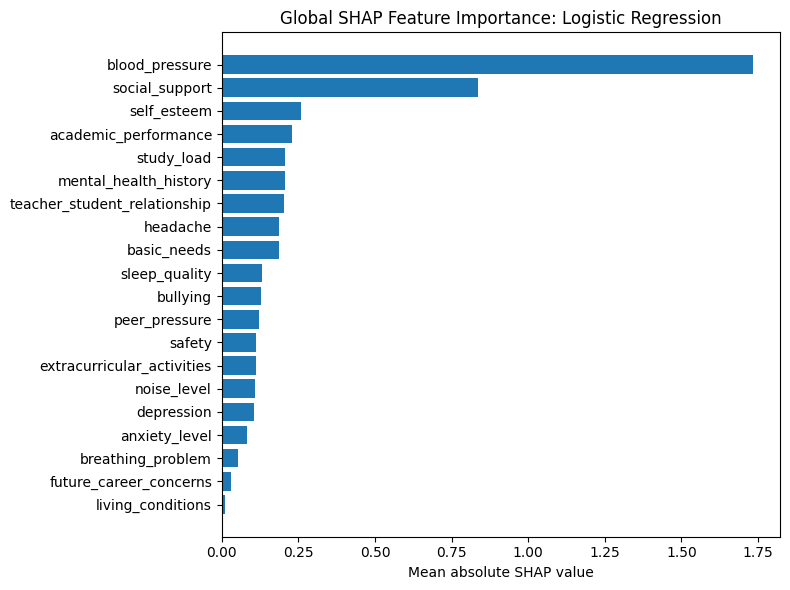

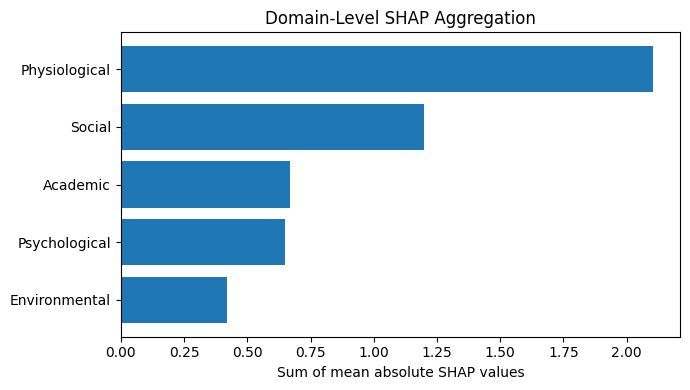

In [16]:
# SHAP global importance এবং domain-level aggregation তৈরি করি
if shap_available:
    mean_abs_by_feature = np.mean(np.abs(shap_values_array), axis=(0, 2))
    shap_importance = pd.DataFrame({
        "feature": shap_feature_names,
        "mean_absolute_shap": mean_abs_by_feature,
    }).sort_values("mean_absolute_shap", ascending=False)

    feature_to_domain = {
        feature: domain
        for domain, features in domain_mapping.items()
        for feature in features
    }
    shap_importance["domain"] = shap_importance["feature"].map(feature_to_domain)

    domain_shap_importance = (
        shap_importance.groupby("domain", as_index=False)["mean_absolute_shap"]
        .sum()
        .sort_values("mean_absolute_shap", ascending=False)
    )

    display(shap_importance)
    display(domain_shap_importance)

    fig, ax = plt.subplots(figsize=(8, 6))
    plot_data = shap_importance.sort_values("mean_absolute_shap", ascending=True)
    ax.barh(plot_data["feature"], plot_data["mean_absolute_shap"])
    ax.set_xlabel("Mean absolute SHAP value")
    ax.set_title(f"Global SHAP Feature Importance: {best_model_name}")
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 4))
    plot_domains = domain_shap_importance.sort_values("mean_absolute_shap", ascending=True)
    ax.barh(plot_domains["domain"], plot_domains["mean_absolute_shap"])
    ax.set_xlabel("Sum of mean absolute SHAP values")
    ax.set_title("Domain-Level SHAP Aggregation")
    plt.tight_layout()
    plt.show()
else:
    shap_importance = pd.DataFrame(columns=["feature", "mean_absolute_shap", "domain"])
    domain_shap_importance = pd.DataFrame(columns=["domain", "mean_absolute_shap"])
    print("SHAP summary tables are unavailable because SHAP calculation did not complete.")

In [17]:
# প্রতিটি class-এর জন্য আলাদা global SHAP importance দেখাই
if shap_available:
    class_shap_rows = []
    for class_index, class_label in enumerate(shap_class_labels):
        class_values = np.mean(np.abs(shap_values_array[:, :, class_index]), axis=0)
        for feature, importance in zip(shap_feature_names, class_values):
            class_shap_rows.append({
                "class": class_label,
                "feature": feature,
                "mean_absolute_shap": float(importance),
            })

    class_shap_importance = pd.DataFrame(class_shap_rows)
    display(
        class_shap_importance.sort_values(
            ["class", "mean_absolute_shap"], ascending=[True, False]
        ).groupby("class").head(10)
    )
else:
    class_shap_importance = pd.DataFrame(columns=["class", "feature", "mean_absolute_shap"])

,class,feature,mean_absolute_shap
5,0,blood_pressure,1.348240
16,0,social_support,0.993864
12,0,academic_performance,0.342274
13,0,study_load,0.309642
11,0,basic_needs,0.281754
2,0,mental_health_history,0.215353
4,0,headache,0.210645
14,0,teacher_student_relationship,0.173002
10,0,safety,0.168542
1,0,self_esteem,0.166797


# ধাপ 8: Robustness ও ফলাফলের সারাংশ

এই ধাপে baseline model-এর seed-wise variability এবং domain ablation-এর প্রধান ফলাফল সংক্ষেপে দেখানো হবে। তিনটি seed দিয়ে পাওয়া variation সীমিত robustness check; এটি পূর্ণাঙ্গ external validation বা formal statistical significance test-এর বিকল্প নয়।

In [18]:
# Baseline seed variability এবং ablation-এর প্রধান configuration সংক্ষেপ করি
baseline_robustness = (
    baseline_seed_results.groupby("model")
    .agg(
        weighted_f1_mean=("f1_weighted_mean", "mean"),
        weighted_f1_std_across_seeds=("f1_weighted_mean", "std"),
        macro_f1_mean=("f1_macro_mean", "mean"),
        balanced_accuracy_mean=("balanced_accuracy_mean", "mean"),
    )
    .reset_index()
    .sort_values("weighted_f1_mean", ascending=False)
)

ablation_best_by_configuration = (
    ablation_summary.sort_values("f1_weighted_mean", ascending=False)
    .groupby("configuration", as_index=False)
    .first()
    .sort_values("f1_weighted_mean", ascending=False)
)

display(baseline_robustness.round(4))
display(ablation_best_by_configuration[
    ["configuration", "model", "feature_count", "f1_weighted_mean", "f1_weighted_std", "f1_macro_mean"]
].round(4))

,model,weighted_f1_mean,weighted_f1_std_across_seeds,macro_f1_mean,balanced_accuracy_mean
1,Logistic Regression,0.8830,0.0049,0.8831,0.8829
0,HistGradientBoosting,0.8814,0.0054,0.8814,0.8814
2,Random Forest,0.8731,0.0047,0.8731,0.8729


,configuration,model,feature_count,f1_weighted_mean,f1_weighted_std,f1_macro_mean
6,Without Academic,Logistic Regression,16,0.8873,0.0016,0.8874
7,Without Environmental,Logistic Regression,16,0.8865,0.0010,0.8866
10,Without Social,Logistic Regression,16,0.8859,0.0036,0.8859
3,Physiological only,Logistic Regression,4,0.8849,0.0018,0.8851
1,All features,Logistic Regression,20,0.8830,0.0049,0.8831
9,Without Psychological,Logistic Regression,16,0.8787,0.0030,0.8788
4,Psychological only,Logistic Regression,4,0.8763,0.0022,0.8762
2,Environmental only,Logistic Regression,4,0.8758,0.0035,0.8758
8,Without Physiological,Logistic Regression,16,0.8698,0.0031,0.8697
0,Academic only,Logistic Regression,4,0.8692,0.0008,0.8689


# ধাপ 9: Hypothetical what-if sensitivity analysis

এই বিশ্লেষণে নির্বাচিত model-এর কাছে কিছু feature-এর observed 25th percentile এবং 75th percentile মান দিয়ে hypothetical profile পাঠানো হবে। একবারে একটি feature পরিবর্তন করা হবে; অন্য feature-গুলো training data-এর median-এ স্থির থাকবে।

এটি model sensitivity analysis মাত্র। এটি বাস্তব ব্যক্তির জন্য সুপারিশ নয়, feature পরিবর্তন করলে stress কমবে এমন causal evidence নয়, এবং feature-এর কোন দিকটি স্বাস্থ্যকর তা dataset documentation ছাড়া ধরে নেওয়া হবে না।

In [19]:
# Training data-এর median থেকে একটি hypothetical baseline profile তৈরি করি
modifiable_features = [
    feature for feature in [
        "anxiety_level",
        "self_esteem",
        "sleep_quality",
        "social_support",
        "peer_pressure",
        "study_load",
    ]
    if feature in X_train.columns
]

baseline_profile = X_train.median(numeric_only=True).to_frame().T
baseline_profile = baseline_profile[X_train.columns]

what_if_records = []
baseline_probabilities = final_pipeline.predict_proba(baseline_profile)[0]
classes = final_pipeline.named_steps["model"].classes_
baseline_predicted_class = final_pipeline.predict(baseline_profile)[0]

what_if_records.append({
    "scenario": "Baseline median profile",
    "changed_feature": "None",
    "feature_value": np.nan,
    "predicted_class": baseline_predicted_class,
    "maximum_class_probability": float(np.max(baseline_probabilities)),
})

for feature in modifiable_features:
    lower_value = float(X_train[feature].quantile(0.25))
    upper_value = float(X_train[feature].quantile(0.75))

    for scenario, value in [("Lower quartile", lower_value), ("Upper quartile", upper_value)]:
        hypothetical_profile = baseline_profile.copy()
        hypothetical_profile.loc[:, feature] = value
        probabilities = final_pipeline.predict_proba(hypothetical_profile)[0]

        what_if_records.append({
            "scenario": scenario,
            "changed_feature": feature,
            "feature_value": value,
            "predicted_class": final_pipeline.predict(hypothetical_profile)[0],
            "maximum_class_probability": float(np.max(probabilities)),
        })

what_if_results = pd.DataFrame(what_if_records)
display(what_if_results.round(4))

,scenario,changed_feature,feature_value,predicted_class,maximum_class_probability
0,Baseline median profile,None,NaN,1,0.7945
1,Lower quartile,anxiety_level,6.0,1,0.7627
2,Upper quartile,anxiety_level,17.0,1,0.8283
3,Lower quartile,self_esteem,11.0,1,0.7536
4,Upper quartile,self_esteem,26.0,1,0.8155
5,Lower quartile,sleep_quality,1.0,1,0.7906
6,Upper quartile,sleep_quality,4.0,1,0.7939
7,Lower quartile,social_support,1.0,1,0.9685
8,Upper quartile,social_support,3.0,0,0.6078
9,Lower quartile,peer_pressure,2.0,1,0.7945


# ধাপ 10: গবেষণার artifact সংরক্ষণ

মূল ফলাফলগুলো CSV file হিসেবে সংরক্ষণ করা হবে, যাতে paper table তৈরির সময় একই notebook আবার চালিয়ে ফলাফল পাওয়া যায়। এই file-গুলো notebook-এর current working directory-তে তৈরি হবে।

In [20]:
# প্রধান গবেষণা ফলাফলগুলো CSV ফাইলে সংরক্ষণ করি
output_dir = Path("research_outputs")
output_dir.mkdir(exist_ok=True)

audit_summary.to_csv(output_dir / "data_audit_summary.csv", index=False)
mapping_table.to_csv(output_dir / "feature_domain_mapping.csv", index=False)
baseline_seed_results.to_csv(output_dir / "baseline_seed_results.csv", index=False)
baseline_summary.to_csv(output_dir / "baseline_summary.csv", index=False)
holdout_metrics_table.to_csv(output_dir / "holdout_metrics.csv", index=False)
ablation_seed_results.to_csv(output_dir / "ablation_seed_results.csv", index=False)
ablation_summary.to_csv(output_dir / "ablation_summary.csv", index=False)
removal_comparison.to_csv(output_dir / "domain_removal_comparison.csv", index=False)
what_if_results.to_csv(output_dir / "what_if_sensitivity.csv", index=False)

if not shap_importance.empty:
    shap_importance.to_csv(output_dir / "shap_feature_importance.csv", index=False)
if not domain_shap_importance.empty:
    domain_shap_importance.to_csv(output_dir / "shap_domain_importance.csv", index=False)
if not class_shap_importance.empty:
    class_shap_importance.to_csv(output_dir / "shap_class_importance.csv", index=False)

print("Research outputs saved to:", output_dir.resolve())
print("Files created:", len(list(output_dir.glob("*.csv"))))

Research outputs saved to: /mnt/data/research_outputs
Files created: 12


# চূড়ান্ত গবেষণা সতর্কতা ও পরবর্তী কাজ

- Target class 0, 1, 2-এর অর্থ dataset documentation দিয়ে নিশ্চিত করতে হবে।
- Domain mapping semantic এবং গবেষণার operational decision; mapping sensitivity analysis ভবিষ্যতে করা যেতে পারে।
- Holdout result একবারই final evaluation হিসেবে ব্যবহার করতে হবে।
- Cross-validation seed variability সীমিত robustness evidence; external dataset-এ validation প্রয়োজন।
- SHAP values model behavior ব্যাখ্যা করে, causality নয়।
- What-if results hypothetical এবং causal intervention evidence নয়।
- এই notebook-এ hyperparameter optimization করা হয়নি; baseline comparison-এর পর আলাদা protocol নির্ধারণ করে তা যোগ করা উচিত।